# 📘 Notebook 10: Batch Normalisation and Learning-Rate Schedules

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** About **twenty minutes** on an ordinary processor. Small networks and short trainings; schedules matter more in long trainings of large models, where they are always used.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain **batch normalisation** and why it makes training faster and less sensitive to the learning rate
- Measure how batch normalisation **widens** the range of good learning rates
- Explain **learning-rate schedules**: step decay, cosine annealing, **warm-up**, and the one-cycle policy
- Compare a constant learning rate with schedules on the same budget

> **Prerequisites:** [Notebook 03: The Learning Rate](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/03_learning_rate.ipynb) and [Notebook 08: Initialisation](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/08_initialisation.ipynb).
>
> 🔭 **Why this notebook matters:** these are the two tools that turned deep learning from an art of careful tuning into a routine. Almost every modern training recipe uses a normalisation layer and a learning-rate schedule.

## 1. The papers

> 📄 S. Ioffe and C. Szegedy, [*Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift*](https://arxiv.org/abs/1502.03167), ICML 2015.
>
> 📄 I. Loshchilov and F. Hutter, [*SGDR: Stochastic Gradient Descent with Warm Restarts*](https://arxiv.org/abs/1608.03983), ICLR 2017 (cosine annealing).
>
> 📄 L. N. Smith and N. Topin, [*Super-Convergence: Very Fast Training of Neural Networks Using Large Learning Rates*](https://arxiv.org/abs/1708.07120), 2017 (one-cycle).

### Intuition first
**Batch normalisation:** after a linear layer, rescale each neuron's outputs over the current batch to mean 0 and standard deviation 1, then let the network learn its own scale and shift. Every layer then receives inputs of a predictable size, whatever happens in the layers before it, so larger learning rates become safe.

**Schedules:** a large learning rate makes fast progress early but cannot settle into a precise minimum; a small one settles but crawls. A schedule uses both: large at first, smaller later. **Warm-up** starts small for the first steps, while the weights are still random, then rises.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


## 2. Batch normalisation widens the safe range of learning rates

A network with four hidden layers of 256 neurons, with and without batch normalisation, trained with plain SGD for 10 epochs at learning rates from 0.003 to 3.

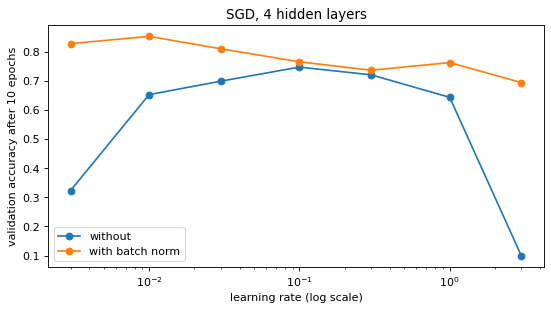

,without,with batch norm
learning rate,,
0.003,0.323,0.828
0.010,0.653,0.853
0.030,0.699,0.811
0.100,0.748,0.766
0.300,0.721,0.737
1.000,0.644,0.763
3.000,0.099,0.694


In [2]:
rates = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
bn_rows = {}
for bn in [False, True]:
    for lr in rates:
        h = fit(make_mlp(hidden=(256,) * 4, batchnorm=bn), epochs=10, lr=lr, optimizer="sgd")
        bn_rows.setdefault("with batch norm" if bn else "without", {})[lr] = h["val acc"].iloc[-1]
table = pd.DataFrame(bn_rows).rename_axis("learning rate")
fig, ax = plt.subplots(figsize=(8, 4))
for col in table:
    ax.semilogx(table.index, table[col], marker="o", label=col)
ax.set_xlabel("learning rate (log scale)"); ax.set_ylabel("validation accuracy after 10 epochs"); ax.legend()
ax.set_title("SGD, 4 hidden layers")
plt.show()
table.round(3)

**What we see.** Batch normalisation changes the picture in two ways:
- **It widens the safe range.** Without it, the 4-layer network learns well only between about 0.03 and 0.3, and collapses to **10%** (random guessing) at learning rate 3. With it, every rate from 0.003 to 3 gives a working network: even at 3 it reaches **69%**.
- **It makes small rates work.** At 0.003, plain SGD without normalisation has barely started after 10 epochs (**32%**), while with batch normalisation it already reaches **83%**. Its best result, **85.3%** at 0.01, is ten points above the best without it (74.8% at 0.1).

Batch normalisation does not choose the learning rate for you (accuracy still falls slowly at the largest rates), but it makes the choice far less critical, which is one reason almost every deep network since 2015 uses it or a relative of it (layer normalisation in Transformers).

## 3. Learning-rate schedules

All runs use Adam with a peak learning rate of 0.003 and 20 epochs on a network with two hidden layers of 512 neurons.

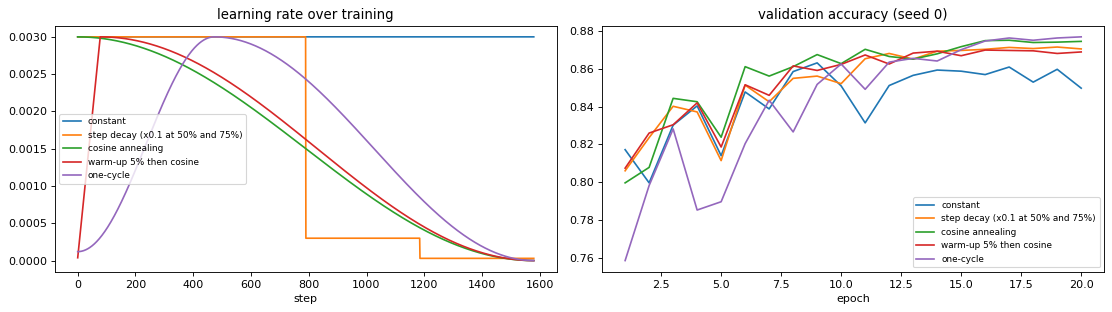

,final val acc (mean of 3 seeds),std,final train loss
constant,0.850,6.600e-03,0.160
step decay (x0.1 at 50% and 75%),0.871,7.000e-04,0.112
cosine annealing,0.872,2.000e-03,0.059
warm-up 5% then cosine,0.870,7.000e-04,0.056
one-cycle,0.874,2.600e-03,0.068


In [3]:
steps = 20 * 79
schedules = {
    "constant": None,
    "step decay (x0.1 at 50% and 75%)": lambda opt, total: torch.optim.lr_scheduler.MultiStepLR(opt, [total // 2, 3 * total // 4], 0.1),
    "cosine annealing": lambda opt, total: torch.optim.lr_scheduler.CosineAnnealingLR(opt, total),
    "warm-up 5% then cosine": lambda opt, total: torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / (0.05 * total) if s < 0.05 * total else 0.5 * (1 + np.cos(np.pi * (s - 0.05 * total) / (0.95 * total)))),
    "one-cycle": lambda opt, total: torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.003, total_steps=total),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sched_rows = {}
for name, make in schedules.items():
    probe = torch.optim.Adam([torch.zeros(1, requires_grad=True)], lr=0.003)
    sch = make(probe, steps) if make else None
    lrs = []
    for _ in range(steps):
        lrs.append(probe.param_groups[0]["lr"]); probe.step()
        if sch:
            sch.step()
    axes[0].plot(lrs, label=name)
    scores = [fit(make_mlp(hidden=(512, 512)), epochs=20, lr=0.003, scheduler=make, seed=s) for s in range(3)]
    axes[1].plot(scores[0].index, scores[0]["val acc"], label=name)
    sched_rows[name] = {"final val acc (mean of 3 seeds)": np.mean([h["val acc"].iloc[-1] for h in scores]),
                        "std": np.std([h["val acc"].iloc[-1] for h in scores]),
                        "final train loss": np.mean([h["train loss"].iloc[-1] for h in scores])}
axes[0].set_title("learning rate over training"); axes[0].set_xlabel("step")
axes[1].set_title("validation accuracy (seed 0)"); axes[1].set_xlabel("epoch")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(sched_rows).T.round(4)

**What we see.** The left panel shows the five learning-rate curves over the 1,580 steps; the right one, the validation accuracy of one seed.
- **Constant** rate: **85.0%** on average, with the largest seed-to-seed spread, and the curve on the right keeps jumping between 83 and 86% until the end: a rate of 0.003 is too large to settle into a precise minimum.
- **Every schedule** that lowers the rate towards the end reaches **87.0 to 87.4%**, about two points better, with smoother curves and a much lower final training loss (0.06 to 0.11 against 0.16). The gain comes from the **end** of training, when the small rate lets the weights settle.
- Between the four schedules the differences (0.4 points) are within noise. **One-cycle** starts slowly and dips around epochs 4 to 5, when its rate peaks, then finishes best (87.4%); **warm-up** brought no visible benefit here, because this small network trained with Adam is stable from the first step. Warm-up matters for large models, Transformers in particular, where the first large steps on random weights can derail training.

The practical rule: **always decay the learning rate** in some way; cosine or one-cycle are simple, strong defaults, and which one matters much less than using one at all.

## ⚠️ Common pitfalls

- **Batch normalisation with very small batches** (a few images): the batch statistics are noisy; use group or layer normalisation instead.
- **Forgetting `model.eval()`**: batch normalisation then uses the statistics of the test batch instead of the averages learned in training.
- **Stepping the scheduler once per epoch when it was built per step** (or the opposite): the schedule runs far too fast or too slowly.
- **A schedule as a substitute for tuning the peak learning rate.** The schedule shapes the rate; the peak still has to be right.

## ✏️ Exercises

### Exercise 1 (Batch norm and depth)
Train networks with 2, 6 and 10 hidden layers of 128 neurons with SGD at learning rate 0.1, with and without batch normalisation, for 10 epochs. How does the benefit change with depth?

In [4]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for depth in [2, 6, 10]:
    row = {bn: fit(make_mlp(hidden=(128,) * depth, batchnorm=bn), epochs=10, lr=0.1, optimizer="sgd")["val acc"].iloc[-1] for bn in [False, True]}
    print(f"{depth} layers: without {row[False]:.4f}, with batch norm {row[True]:.4f}")
```

*In our run the benefit grew with depth: +3 points with 2 layers (69.9% to 73.4%), +12 with 6 layers (62.7% to 74.9%), and with 10 layers the network without normalisation did not learn at all (10%) while the normalised one reached 79%. Shallow networks train fine anyway; deep ones become trainable at all. Normalisation is one of the reasons depth stopped being a problem after 2015.*
</details>

### Exercise 2 (A longer warm-up)
Try warm-up over 1%, 5% and 20% of the steps (followed by cosine) at a high peak learning rate of 0.01. Which works best?

In [5]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def warm_cosine(frac):
    return lambda opt, total: torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / (frac * total) if s < frac * total else 0.5 * (1 + np.cos(np.pi * (s - frac * total) / ((1 - frac) * total))))
for frac in [0.01, 0.05, 0.2]:
    h = fit(make_mlp(hidden=(512, 512)), epochs=20, lr=0.01, scheduler=warm_cosine(frac))
    print(f"warm-up {frac:.0%}: final val acc {h['val acc'].iloc[-1]:.4f}")
```

*In our run all three ended within 0.2 points of each other (86.8%, 86.9%, 87.0%), a difference within noise: for this small network even a peak rate of 0.01 with Adam is stable, so the length of the warm-up hardly matters. Warm-up earns its place in large models, and for Transformers it is essential, as in Notebook 07 of From Papers to Practice.*
</details>

## 🔑 Key takeaways

- **Batch normalisation** keeps each layer's inputs at a stable scale; it makes deep networks train faster and tolerate much larger learning rates.
- **Schedules** start with a large learning rate and end with a small one; cosine annealing and one-cycle are strong, simple defaults.
- **Warm-up** protects the first steps when the peak learning rate is high; on small, stable networks like ours it made no measurable difference.

---
**Next:** *Notebook 11: Automatic Hyperparameter Search with Optuna*, letting the computer search, and doing it honestly.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*